# KDD | Where do Formula 1 drivers gain grid places?

Discover which circuits and starting positions are associated with gaining places among drivers who finish, then check whether the patterns persist.

[Dataset on Kaggle](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [Fayyad, Piatetsky-Shapiro, and Smyth, 1996](https://onlinelibrary.wiley.com/doi/abs/10.1609/aimag.v17i3.1230). Kaggle snapshot version: 24.

## Methodology map

| KDD stage | Evidence |
| --- | --- |
| Selection | Domain question, table roles, discovery and later-period design |
| Preprocessing | Key checks, duplicate and missing values, exclusion accounting |
| Transformation | Grid bands, gain indicator, exact-grid context |
| Data mining | Coverage screen, descriptive patterns, reference sensitivity |
| Interpretation and evaluation | Fixed shortlist, later race-level support, finisher sensitivity, conclusions |

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'rohanrao/formula-1-world-championship-1950-2020'
KAGGLE_VERSION = 24
EXPECTED_SHA256 = {'results.csv': 'a2392658044286800a0a946138067d9823f39e59147eeef0cbdda858ff172441', 'races.csv': '4839d035abc603fa88fa08fa976a86d76cff35f3e94cb767d25f735a5a3376ef', 'circuits.csv': '8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b0213e7a38b3a5c3cba6eb', 'status.csv': 'c36b1287f2421a288c38b0ce875d6ed04ff26bbda3e06db3d99e12197ea894aa'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'results.csv': (26759, 18), 'races.csv': (1125, 18), 'circuits.csv': (77, 9), 'status.csv': (139, 2)}
Kaggle snapshot: 24


## 1. Selection

Use results for grid and finish positions, races for season and circuit keys, circuits for names, and status for result labels. One result row represents one driver in one race. Select the 2014–2023 Grands Prix. Treat 2014–2021 as discovery years and reserve 2022–2023 for evaluation.

In [2]:
results = tables["results.csv"]
races = tables["races.csv"][["raceId", "circuitId", "year"]]
circuits = tables["circuits.csv"][["circuitId", "name"]].rename(columns={"name": "circuit"})
statuses = tables["status.csv"][["statusId", "status"]]
preview_columns = ["raceId", "driverId", "grid", "position", "positionOrder", "statusId"]
display(results[preview_columns].head())

,raceId,driverId,grid,position,positionOrder,statusId
0,18,1,1,1.0,1,1
1,18,2,5,2.0,2,1
2,18,3,7,3.0,3,1
3,18,4,11,4.0,4,1
4,18,5,3,5.0,5,1


### 1.1 Describe the source tables and observation unit

Show the size and key of each table. The unit of analysis is one driver in one Grand Prix.

In [3]:
source_inventory = pd.DataFrame([
    ("results.csv", len(results), "raceId + driverId"),
    ("races.csv", len(races), "raceId"),
    ("circuits.csv", len(circuits), "circuitId"),
    ("status.csv", len(statuses), "statusId"),
], columns=["table", "rows", "key"])
display(source_inventory)

,table,rows,key
0,results.csv,26759,raceId + driverId
1,races.csv,1125,raceId
2,circuits.csv,77,circuitId
3,status.csv,139,statusId


### 1.2 Verify coverage before selecting the study period

Use the race calendar table to confirm that discovery and evaluation seasons have recorded events.

In [4]:
calendar_coverage = races.loc[races.year.between(2014, 2023)].groupby("year").raceId.nunique()
assert calendar_coverage.index.tolist() == list(range(2014, 2024))
display(calendar_coverage.rename("recorded_races").to_frame())

,recorded_races
year,
2014,19
2015,19
2016,21
2017,20
2018,21
2019,21
2020,17
2021,22
2022,22


## 2. Preprocessing

Join each result to one race, one circuit, and one status. A zero grid value identifies a record without a numbered starting position. Report those records as a separate group. Use the Finished and +N Lap status labels as a completion rule. Keep retirement and other statuses outside the primary places-gained analysis and report their count.

In [5]:
entries = (results.merge(races, on="raceId", validate="many_to_one")
           .merge(circuits, on="circuitId", validate="many_to_one")
           .merge(statuses, on="statusId", validate="many_to_one"))
entries = entries.loc[entries.year.between(2014, 2023)].copy()
assert not entries.duplicated(["raceId", "driverId"]).any()
entries["completed"] = entries.status.str.fullmatch(r"Finished|\+\d+ Laps?", na=False)
entries["finish"] = pd.to_numeric(entries.position, errors="coerce")
entries["eligible"] = entries.completed & entries.grid.gt(0) & entries.finish.notna()
scope = {
    "total_driver_entries": len(entries),
    "no_numbered_grid_position": int(entries.grid.eq(0).sum()),
    "other_finish_status": int((~entries.completed).sum()),
    "eligible": int(entries.eligible.sum()),
}
display(pd.Series(scope))

total_driver_entries         4147
no_numbered_grid_position      68
other_finish_status           747
eligible                     3352
dtype: int64

Check the keys and year coverage. A merge with missing keys could otherwise remove rows silently.

In [6]:
assert results.raceId.isin(races.raceId).all()
assert races.circuitId.isin(circuits.circuitId).all()
assert results.statusId.isin(statuses.statusId).all()
coverage = entries.groupby("year").agg(races=("raceId", "nunique"), entries=("driverId", "size"), eligible=("eligible", "sum"))
display(coverage)

,races,entries,eligible
year,,,
2014,19,407,320
2015,19,378,296
2016,21,462,378
2017,20,400,305
2018,21,420,335
2019,21,420,349
2020,17,340,279
2021,22,440,372
2022,22,440,357


### 2.1 Reconcile the analysis exclusions

Apply one rule at a time so the counts do not overlap. The main analysis uses the intersection of all three criteria.

In [7]:
numbered_entries = entries.loc[entries.grid.gt(0)]
finished_entries = numbered_entries.loc[numbered_entries.completed]
eligible_entries = finished_entries.dropna(subset=["finish"])
exclusion_flow = pd.Series({
    "study driver entries": len(entries), "numbered grid": len(numbered_entries),
    "completion status": len(finished_entries), "known finish": len(eligible_entries),
})
assert len(eligible_entries) == scope["eligible"]
display(exclusion_flow.to_frame("remaining"))

,remaining
study driver entries,4147
numbered grid,4079
completion status,3353
known finish,3352


### 2.2 Inspect excluded statuses and race participation

Report which non-completion statuses account for the largest share of exclusions. Some circuits can have different completion rates.

In [8]:
display(entries.loc[~entries.completed, "status"].value_counts().head(10).rename("entries").to_frame())
circuit_quality = entries.groupby("circuit").eligible.agg(entries="size", eligible="sum", eligible_share="mean")
display(circuit_quality.loc[circuit_quality.entries.ge(40)].nsmallest(8, "eligible_share").round(3))

,entries
status,
Collision,138
Engine,76
Accident,76
Collision damage,57
Brakes,47
Power Unit,41
Retired,41
Gearbox,39
Suspension,25


,entries,eligible,eligible_share
circuit,,,
Albert Park Grand Prix Circuit,162,112,0.691
Baku City Circuit,142,105,0.739
Circuit of the Americas,180,135,0.750
Marina Bay Street Circuit,164,124,0.756
Sepang International Circuit,84,64,0.762
Jeddah Corniche Circuit,60,46,0.767
Hockenheimring,84,66,0.786
Circuit de Spa-Francorchamps,204,162,0.794


## 3. Transformation

Places gained equals starting grid position minus finishing position. A positive value means the driver finished ahead of their starting position. Group comparable starting positions into four bands. A driver who starts first cannot gain a place, so comparisons across circuits use the same grid band.

In [9]:
drivers = entries.loc[entries.eligible].copy()
drivers["places_gained"] = drivers.grid - drivers.finish
drivers["gained"] = drivers.places_gained.gt(0)
drivers["grid_band"] = pd.cut(drivers.grid, [0, 5, 10, 15, np.inf], labels=["1–5", "6–10", "11–15", "16+"], right=True)
display(drivers[["year", "circuit", "grid", "finish", "places_gained", "grid_band"]].head(8))

,year,circuit,grid,finish,places_gained,grid_band
22127,2014,Albert Park Grand Prix Circuit,3,1.0,2.0,1–5
22128,2014,Albert Park Grand Prix Circuit,4,2.0,2.0,1–5
22129,2014,Albert Park Grand Prix Circuit,10,3.0,7.0,6–10
22130,2014,Albert Park Grand Prix Circuit,5,4.0,1.0,1–5
22131,2014,Albert Park Grand Prix Circuit,15,5.0,10.0,11–15
22132,2014,Albert Park Grand Prix Circuit,7,6.0,1.0,6–10
22133,2014,Albert Park Grand Prix Circuit,11,7.0,4.0,11–15
22134,2014,Albert Park Grand Prix Circuit,6,8.0,-2.0,6–10


In [10]:
trace_row = drivers.loc[drivers.gained].iloc[0]
assert trace_row.places_gained == trace_row.grid - trace_row.finish
display(trace_row[["circuit", "grid", "finish", "places_gained", "grid_band"]])
print("Grid-zero and other finish-status counts can overlap.")

circuit          Albert Park Grand Prix Circuit
grid                                          3
finish                                      1.0
places_gained                               2.0
grid_band                                   1–5
Name: 22127, dtype: object

Grid-zero and other finish-status counts can overlap.


### 3.1 Verify the transformed outcome

Confirm that the gain indicator matches the signed difference and that a driver on pole cannot gain places.

In [11]:
assert drivers.grid_band.notna().all()
assert drivers.finish.ge(1).all()
assert drivers.gained.eq(drivers.places_gained.gt(0)).all()
assert not drivers.loc[drivers.grid.eq(1), "gained"].any()
display(drivers.places_gained.describe().round(2).rename("places gained"))

count    3352.00
mean        1.36
std         3.89
min       -14.00
25%        -1.00
50%         1.00
75%         4.00
max        19.00
Name: places gained, dtype: float64

### 3.2 Visualize how starting position constrains gains

The chart uses discovery years only. Exact starting slots can have different gain rates even inside the same band.

,entries,rate
grid,,
1,147,0.000
2,145,0.276
3,144,0.299
4,139,0.374
5,133,0.383
6,140,0.436
7,139,0.388
8,130,0.438
9,132,0.561


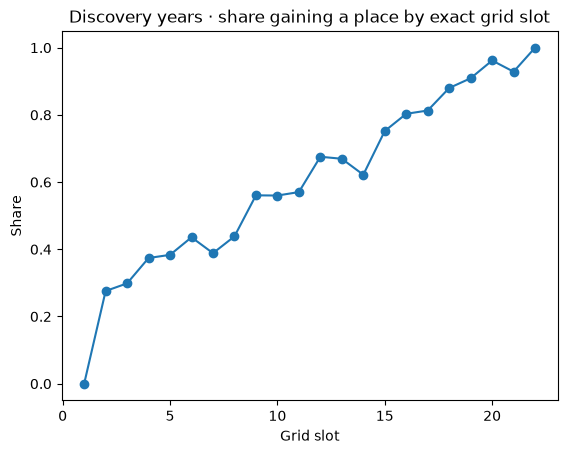

In [12]:
slot_profile = drivers.loc[drivers.year.le(2021)].groupby("grid").gained.agg(entries="size", rate="mean")
display(slot_profile.round(3))
slot_profile.rate.plot(marker="o", title="Discovery years · share gaining a place by exact grid slot", ylabel="Share", xlabel="Grid slot")
plt.show()

## 4. Data mining

Discover circuit and starting-grid groups with a high share of drivers who gained places. Keep groups with at least 20 discovery entries. Rank each group by how far its gain rate exceeds the pooled rate for the same starting band. The pooled rate includes the group. Keep the top five before reading the later-season results.

Ranking many groups highlights extreme estimates. Use the shortlist as an exploratory result. The differences are descriptive and do not establish statistical significance.

In [13]:
def group_summary(frame):
    return frame.groupby(["circuit", "grid_band"], observed=True).agg(
        entries=("gained", "size"),
        gain_rate=("gained", "mean"),
        average_places=("places_gained", "mean"),
    )


discovery = drivers.loc[drivers.year.le(2021)]
later = drivers.loc[drivers.year.ge(2022)]
discovery_bands = discovery.groupby("grid_band", observed=True).gained.mean().rename("band_rate")
patterns = group_summary(discovery).join(discovery_bands, on="grid_band")
patterns["lift"] = patterns.gain_rate - patterns.band_rate
top_patterns = patterns.loc[patterns.entries.ge(20)].sort_values("lift", ascending=False).head(5)
display(top_patterns.round(3))

entries  gain_rate  average_places  \
circuit                       grid_band                                       
Bahrain International Circuit 1–5             38      0.474          -0.553   
Marina Bay Street Circuit     11–15           21      0.810           3.286   
Circuit of the Americas       6–10            24      0.625           0.417   
                              11–15           26      0.808           2.231   
Autódromo Hermanos Rodríguez  6–10            26      0.615           0.385   

                                         band_rate   lift  
circuit                       grid_band                    
Bahrain International Circuit 1–5            0.263  0.211  
Marina Bay Street Circuit     11–15          0.657  0.152  
Circuit of the Americas       6–10           0.474  0.151  
                              11–15          0.657  0.150  
Autódromo Hermanos Rodríguez  6–10           0.474  0.141

### 4.1 Review support before ranking

Count candidate groups and show the number of distinct races behind the shortlist. Driver entries from the same event share conditions.

In [14]:
discovery_support = discovery.groupby(["circuit", "grid_band"], observed=True).raceId.nunique().rename("races")
assert len(top_patterns) == 5
print("Total groups:", len(patterns), "| Groups with at least 20 entries:", patterns.entries.ge(20).sum())
display(top_patterns[["entries", "lift"]].join(discovery_support).round(3))

Total groups: 120 | Groups with at least 20 entries: 71


entries   lift  races
circuit                       grid_band                       
Bahrain International Circuit 1–5             38  0.211      9
Marina Bay Street Circuit     11–15           21  0.152      6
Circuit of the Americas       6–10            24  0.151      7
                              11–15           26  0.150      7
Autódromo Hermanos Rodríguez  6–10            26  0.141      6

### 4.2 Check the shortlist against an outside-circuit reference

Recalculate the discovery reference after removing each focal circuit. This is a sensitivity check on the fixed shortlist.

In [15]:
reference_rows = []
for circuit, band in top_patterns.index:
    other = discovery.loc[discovery.circuit.ne(circuit) & discovery.grid_band.eq(band)]
    reference_rows.append({
        "circuit": circuit, "grid_band": band, "reference_entries": len(other),
        "outside_circuit_rate": other.gained.mean(),
        "gain_rate": top_patterns.loc[(circuit, band), "gain_rate"],
    })
reference_check = pd.DataFrame(reference_rows)
reference_check["outside_circuit_lift"] = reference_check.gain_rate - reference_check.outside_circuit_rate
display(reference_check.round(3))

,circuit,grid_band,reference_entries,outside_circuit_rate,gain_rate,outside_circuit_lift
0,Bahrain International Circuit,1–5,670,0.251,0.474,0.223
1,Marina Bay Street Circuit,11–15,586,0.652,0.810,0.158
2,Circuit of the Americas,6–10,642,0.469,0.625,0.156
3,Circuit of the Americas,11–15,581,0.651,0.808,0.157
4,Autódromo Hermanos Rodríguez,6–10,640,0.469,0.615,0.147


All five discovery gaps stay positive when the focal circuit leaves the reference pool. This check uses the same period that selected the groups. The separate later-period table tests whether they still stand out.

## 5. Interpretation and evaluation

Check the same five groups in 2022–2023. Label a group inconclusive when it has fewer than 10 later entries. For groups with enough entries, report whether their gain rate remains above the later pooled rate for the same starting band. This comparison describes associations among finishers. It cannot tell us whether the circuit caused a driver to gain places.

There are only two later races behind each candidate group. A five-slot band at a circuit with two races has at most ten numbered starts before exclusions. Even the group that reaches ten is too small for a firm conclusion about persistence.

In [16]:
later_bands = later.groupby("grid_band", observed=True).gained.mean().rename("band_rate")
later_summary = group_summary(later).join(later_bands, on="grid_band")
comparison = top_patterns.add_prefix("discovery_").join(later_summary.add_prefix("later_"))
comparison["later_entries"] = comparison.later_entries.fillna(0).astype(int)
comparison["later_lift"] = comparison.later_gain_rate - comparison.later_band_rate
comparison["assessment"] = np.select(
    [comparison.later_entries.lt(10), comparison.later_lift.gt(0)],
    ["Inconclusive", "Still above band rate"],
    default="Did not stay above band rate",
)
display(comparison.round(3))

discovery_entries  \
circuit                       grid_band                      
Bahrain International Circuit 1–5                       38   
Marina Bay Street Circuit     11–15                     21   
Circuit of the Americas       6–10                      24   
                              11–15                     26   
Autódromo Hermanos Rodríguez  6–10                      26   

                                         discovery_gain_rate  \
circuit                       grid_band                        
Bahrain International Circuit 1–5                      0.474   
Marina Bay Street Circuit     11–15                    0.810   
Circuit of the Americas       6–10                     0.625   
                              11–15                    0.808   
Autódromo Hermanos Rodríguez  6–10                     0.615   

                                         discovery_average_places  \
circuit                       grid_band                             
Bahrain International Circuit 1–5                          -0.553   
Marina Bay Street Circuit     11–15                         3.286   
Circuit of the Americas       6–10                          0.417   
                              11–15                         2.231   
Autódromo Hermanos Rodríguez  6–10                          0.385   

                                         discovery_band_rate  discovery_lift  \
circuit                       grid_band                                        
Bahrain International Circuit 1–5                      0.263           0.211   
Marina Bay Street Circuit     11–15                    0.657           0.152   
Circuit of the Americas       6–10                     0.474           0.151   
                              11–15                    0.657           0.150   
Autódromo Hermanos Rodríguez  6–10                     0.474           0.141   

                                         later_entries  later_gain_rate  \
circuit                       grid_band                                   
Bahrain International Circuit 1–5                    7            0.429   
Marina Bay Street Circuit     11–15                  8            0.875   
Circuit of the Americas       6–10                   7            0.714   
                              11–15                 10            0.600   
Autódromo Hermanos Rodríguez  6–10                   9            0.444   

                                         later_average_places  \
circuit                       grid_band                         
Bahrain International Circuit 1–5                       0.714   
Marina Bay Street Circuit     11–15                     4.125   
Circuit of the Americas       6–10                      1.857   
                              11–15                     2.400   
Autódromo Hermanos Rodríguez  6–10                     -0.778   

                                         later_band_rate  later_lift  \
circuit                       grid_band                                
Bahrain International Circuit 1–5                  0.274       0.155   
Marina Bay Street Circuit     11–15                0.627       0.248   
Circuit of the Americas       6–10                 0.484       0.230   
                              11–15                0.627      -0.027   
Autódromo Hermanos Rodríguez  6–10                 0.484      -0.039   

                                                           assessment  
circuit                       grid_band                                
Bahrain International Circuit 1–5                        Inconclusive  
Marina Bay Street Circuit     11–15                      Inconclusive  
Circuit of the Americas       6–10                       Inconclusive  
                              11–15      Did not stay above band rate  
Autódromo Hermanos Rodríguez  6–10                       Inconclusive

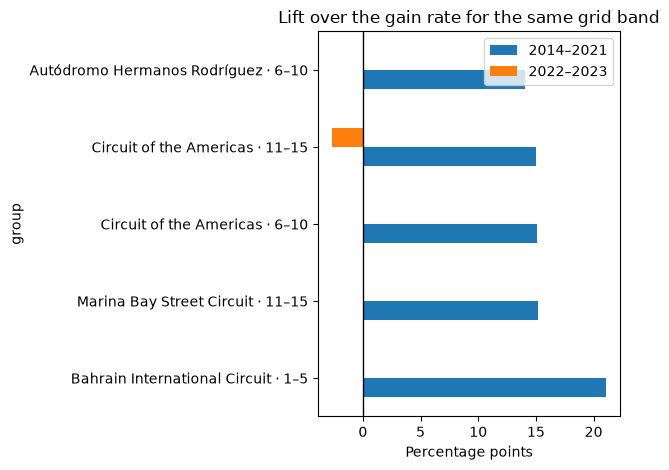

In [17]:
plot_data = comparison.reset_index()
plot_data["group"] = plot_data.circuit.astype(str) + " · " + plot_data.grid_band.astype(str)
plot_data["later_plot_lift"] = plot_data.later_lift.where(plot_data.later_entries.ge(10))
ax = plot_data.set_index("group")[["discovery_lift", "later_plot_lift"]].rename(
    columns={"discovery_lift": "2014–2021", "later_plot_lift": "2022–2023"}
).mul(100).plot.barh(title="Lift over the gain rate for the same grid band", xlabel="Percentage points")
ax.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()
comparison.to_csv(ARTIFACTS / "pattern_comparison.csv")
save_json("scope.json", scope)

Entries from the same Grand Prix share race conditions. Count distinct races behind each later result. Use this as a second measure of how much evidence each group has.

In [18]:
later_events = later.groupby(["circuit", "grid_band"], observed=True).raceId.nunique()
later_support = comparison[["later_entries", "later_gain_rate", "assessment"]].join(later_events.rename("later_races"))
display(later_support.round(3))
later_support.to_csv(ARTIFACTS / "later_race_support.csv")

numbered = entries.loc[entries.grid.gt(0)].copy()
numbered["grid_band"] = pd.cut(numbered.grid, [0, 5, 10, 15, np.inf], labels=["1–5", "6–10", "11–15", "16+"], right=True)
numbered["gain_with_other_finishes_as_no_gain"] = numbered.eligible & numbered.grid.gt(numbered.finish)
sensitivity = numbered.loc[numbered.year.ge(2022)].groupby(["circuit", "grid_band"], observed=True).agg(
    numbered_starts=("eligible", "size"),
    eligible_finishes=("eligible", "sum"),
    gain_rate_all_numbered=("gain_with_other_finishes_as_no_gain", "mean"),
)
sensitivity = later_support.join(sensitivity)
display(sensitivity[["numbered_starts", "eligible_finishes", "later_gain_rate", "gain_rate_all_numbered"]].round(3))
sensitivity.to_csv(ARTIFACTS / "later_race_support.csv")

later_entries  later_gain_rate  \
circuit                       grid_band                                   
Bahrain International Circuit 1–5                    7            0.429   
Marina Bay Street Circuit     11–15                  8            0.875   
Circuit of the Americas       6–10                   7            0.714   
                              11–15                 10            0.600   
Autódromo Hermanos Rodríguez  6–10                   9            0.444   

                                                           assessment  \
circuit                       grid_band                                 
Bahrain International Circuit 1–5                        Inconclusive   
Marina Bay Street Circuit     11–15                      Inconclusive   
Circuit of the Americas       6–10                       Inconclusive   
                              11–15      Did not stay above band rate   
Autódromo Hermanos Rodríguez  6–10                       Inconclusive   

                                         later_races  
circuit                       grid_band               
Bahrain International Circuit 1–5                  2  
Marina Bay Street Circuit     11–15                2  
Circuit of the Americas       6–10                 2  
                              11–15                2  
Autódromo Hermanos Rodríguez  6–10                 2

numbered_starts  eligible_finishes  \
circuit                       grid_band                                       
Bahrain International Circuit 1–5                     10                  7   
Marina Bay Street Circuit     11–15                   10                  8   
Circuit of the Americas       6–10                    10                  7   
                              11–15                   10                 10   
Autódromo Hermanos Rodríguez  6–10                    10                  9   

                                         later_gain_rate  \
circuit                       grid_band                    
Bahrain International Circuit 1–5                  0.429   
Marina Bay Street Circuit     11–15                0.875   
Circuit of the Americas       6–10                 0.714   
                              11–15                0.600   
Autódromo Hermanos Rodríguez  6–10                 0.444   

                                         gain_rate_all_numbered  
circuit                       grid_band                          
Bahrain International Circuit 1–5                           0.3  
Marina Bay Street Circuit     11–15                         0.7  
Circuit of the Americas       6–10                          0.5  
                              11–15                         0.6  
Autódromo Hermanos Rodríguez  6–10                          0.4

The thresholds describe minimum coverage, not statistical significance. The top five groups reflect the largest discovery gaps, which can shrink on fresh data. Compare later rates with their sample sizes. A driver can gain places because others retire, so places gained is not a count of on-track passes.

The sensitivity table includes all numbered starts and counts a non-finish or other excluded finish status as no gain. It shows how the outcome changes when we change the denominator. The main result still describes eligible finishers.

### 5.1 Trace the later results race by race

Inspect whether the aggregate is spread across events. The later period supplies only two races for each candidate.

In [19]:
shortlist = top_patterns.reset_index()[["circuit", "grid_band"]]
matched_later = later.merge(shortlist, on=["circuit", "grid_band"], how="inner", validate="many_to_one")
event_details = matched_later.groupby(["circuit", "grid_band", "year", "raceId"], observed=True).gained.agg(
    entries="size", gain_count="sum", gain_rate="mean"
)
display(event_details.round(3))

entries  gain_count  \
circuit                       grid_band year raceId                        
Autódromo Hermanos Rodríguez  6–10      2022 1094          4           2   
                                        2023 1117          5           2   
Bahrain International Circuit 1–5       2022 1074          3           2   
                                        2023 1098          4           1   
Circuit of the Americas       6–10      2022 1093          4           2   
                                        2023 1116          3           3   
                              11–15     2022 1093          5           3   
                                        2023 1116          5           3   
Marina Bay Street Circuit     11–15     2022 1091          4           3   
                                        2023 1113          4           4   

                                                     gain_rate  
circuit                       grid_band year raceId             
Autódromo Hermanos Rodríguez  6–10      2022 1094        0.500  
                                        2023 1117        0.400  
Bahrain International Circuit 1–5       2022 1074        0.667  
                                        2023 1098        0.250  
Circuit of the Americas       6–10      2022 1093        0.500  
                                        2023 1116        1.000  
                              11–15     2022 1093        0.600  
                                        2023 1116        0.600  
Marina Bay Street Circuit     11–15     2022 1091        0.750  
                                        2023 1113        1.000

### 5.2 Check exact-slot composition in the later period

Use the pooled rate for each exact grid slot as a second descriptive comparison. This accounts for differences such as a group having more first-place than fifth-place starters.

In [20]:
later_slot_rates = later.groupby("grid").gained.mean()
matched_later = matched_later.assign(slot_reference=matched_later.grid.map(later_slot_rates))
slot_comparison = matched_later.groupby(["circuit", "grid_band"], observed=True).agg(
    entries=("gained", "size"), actual=("gained", "mean"), slot_reference=("slot_reference", "mean")
)
slot_comparison["slot_adjusted_gap"] = slot_comparison.actual - slot_comparison.slot_reference
display(slot_comparison.round(3))

entries  actual  slot_reference  \
circuit                       grid_band                                    
Autódromo Hermanos Rodríguez  6–10             9   0.444           0.481   
Bahrain International Circuit 1–5              7   0.429           0.253   
Circuit of the Americas       6–10             7   0.714           0.484   
                              11–15           10   0.600           0.630   
Marina Bay Street Circuit     11–15            8   0.875           0.601   

                                         slot_adjusted_gap  
circuit                       grid_band                     
Autódromo Hermanos Rodríguez  6–10                  -0.037  
Bahrain International Circuit 1–5                    0.175  
Circuit of the Americas       6–10                   0.230  
                              11–15                 -0.030  
Marina Bay Street Circuit     11–15                  0.274

For Circuit of the Americas in the 11–15 band, the observed rate is 60.0% and the exact-slot reference is 63.0%. This comparison agrees with the direction of the primary later-period result. Ten entries across two races leave substantial uncertainty.

### 5.3 Record what the evidence supports

Summarize the held-out decisions and retain the denominator and race counts with each result.

In [21]:
display(comparison.assessment.value_counts().rename("groups").to_frame())
display(later_support[["later_entries", "later_races", "assessment"]])

,groups
assessment,
Inconclusive,4
Did not stay above band rate,1


later_entries  later_races  \
circuit                       grid_band                               
Bahrain International Circuit 1–5                    7            2   
Marina Bay Street Circuit     11–15                  8            2   
Circuit of the Americas       6–10                   7            2   
                              11–15                 10            2   
Autódromo Hermanos Rodríguez  6–10                   9            2   

                                                           assessment  
circuit                       grid_band                                
Bahrain International Circuit 1–5                        Inconclusive  
Marina Bay Street Circuit     11–15                      Inconclusive  
Circuit of the Americas       6–10                       Inconclusive  
                              11–15      Did not stay above band rate  
Autódromo Hermanos Rodríguez  6–10                       Inconclusive

### 5.4 Communicate the result and next check

The shortlist shows where to look in additional seasons. Each candidate has only two later races, and the finisher rule changes the rates for some groups. Treat both the pooled and exact-slot comparisons as descriptive. A stronger follow-up would reserve more race weekends and compare exact grid slots with uncertainty at the race level.